Every model in this course, from a moving-average rule to a gradient-boosted ranking of stocks, makes assumptions about returns. A model that assumes returns are normal, independent and stable will be confidently wrong in exactly the moments that matter most. So before building anything we study the raw material: 76 years of daily S&P 500 returns, a century of US market returns from the Fama–French data library, and seven assets from stocks to Bitcoin.

The chapter has two halves. The first describes returns: the **stylised facts** that hold in almost every market. The second is about **inference**: how much a sample of returns can tell you. Its answer (much less than you think) shapes every later chapter.

:::eli5
Imagine a coin that is very slightly unfair: it lands heads 51 times in 100. Toss it ten times and you cannot tell it from a fair coin. Toss it ten thousand times and you can. Market returns are like a slightly unfair coin flipped in a storm: the edge is tiny, the noise is huge, and the storm keeps changing strength. This chapter measures the storm and works out how many tosses you need.
:::

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path
from scipy import stats, optimize, special

mpl.rc("axes", labelsize=12, titlesize=13); mpl.rc("figure", dpi=110)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
DATA = Path("datasets")
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
rng = np.random.default_rng(42)
R = {}

## Get the data

Three real datasets, all in `datasets/`: the S&P 500 index level since 1950 (Yahoo Finance), daily prices of seven assets since 2005 adjusted for dividends (Yahoo Finance), and the daily market excess return since 1926 from Kenneth French's data library (the value-weighted return of all US stocks minus the Treasury-bill rate).

In [2]:
spx = pd.read_csv(DATA / "sp500_index_daily.csv", index_col="date", parse_dates=True)["close"]
assets = pd.read_csv(DATA / "assets_daily.csv", index_col="date", parse_dates=True)
ff = pd.read_csv(DATA / "ff_factors_daily.csv", index_col="date", parse_dates=True)
print(spx.index[0].date(), "→", spx.index[-1].date(), len(spx), "days")
print(assets.columns.tolist())
print(ff.index[0].date(), "→", ff.index[-1].date(), len(ff), "days")

1950-01-03 → 2026-10-30 19330 days
['AAPL', 'BTC-USD', 'EEM', 'EURUSD=X', 'GLD', 'SPY', 'TLT']
1926-07-01 → 2026-09-30 26338 days


## From prices to returns

:::math
Simple return $R_t = P_t / P_{t-1} - 1$ and log return $r_t = \ln(P_t / P_{t-1}) = \ln(1 + R_t)$. Two aggregation rules decide which one to use:

- **Over time, log returns add**: $r_{t \to t+k} = \sum_{j=1}^{k} r_{t+j}$, because $\ln$ turns the product $\prod (1 + R)$ into a sum. This makes log returns the natural choice for statistics of one asset over time.
- **Across assets, simple returns average**: a portfolio with weights $w_i$ earns $R_p = \sum_i w_i R_i$. Log returns do not average this way. Portfolio and backtest P&L therefore use simple returns.

For daily moves the two are nearly equal, since $\ln(1 + R) = R - R^2/2 + \dots$
:::

mean 0.00032  sd 0.0100  min -0.229 (1987-10-19)  max 0.110


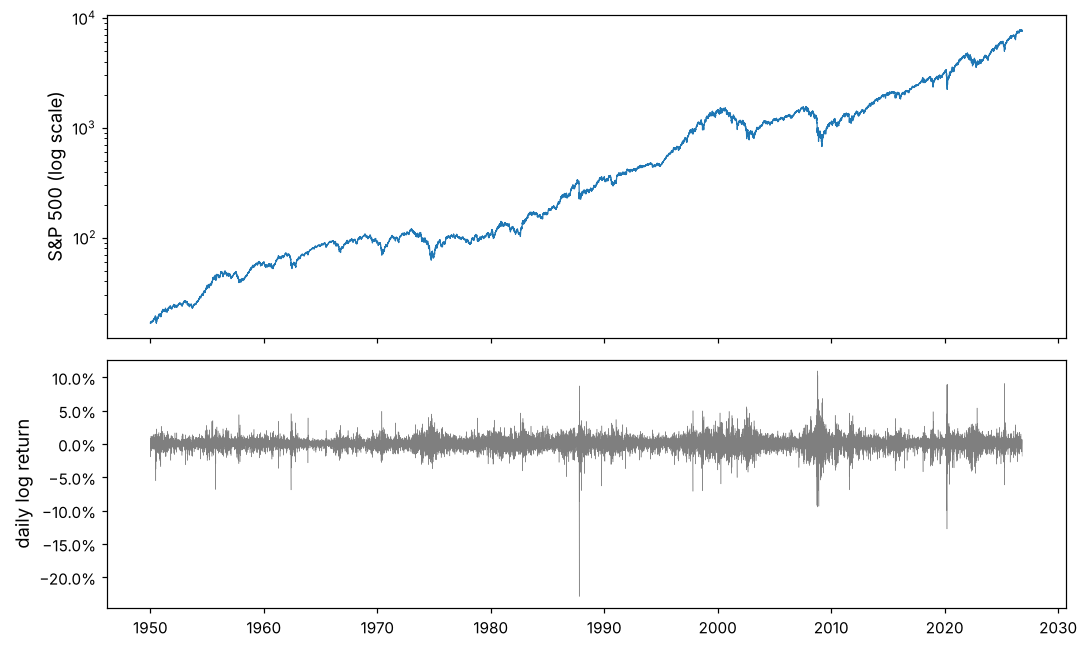

In [3]:
r = np.log(spx).diff().dropna()                  # daily log returns of the S&P 500
print(f"mean {r.mean():.5f}  sd {r.std():.4f}  min {r.min():.3f} ({r.idxmin().date()})  max {r.max():.3f}")
R["crash87"] = f"{np.expm1(r.min()):.1%}"
R["n_years"] = f"{(r.index[-1] - r.index[0]).days / 365.25:.0f}"

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
ax[0].plot(spx, lw=0.8); ax[0].set_yscale("log"); ax[0].set_ylabel("S&P 500 (log scale)")
ax[1].plot(r, lw=0.3, color="tab:gray"); ax[1].set_ylabel("daily log return")
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
save_fig("spx_returns"); plt.show()

![Figure 1-1. 76 years of the S&P 500. Top: the index on a log scale. Bottom: daily returns. Calm and wild periods alternate; 19 October 1987 stands out.](images/spx_returns.png)

The largest daily fall, Black Monday in 1987, was -20.5%. Look at the bottom panel before reading on: the returns are not a uniform cloud of noise. They come in quiet stretches and violent bursts. That observation, **volatility clustering**, is the first of the stylised facts.

### Annualising: the square-root-of-time rule

If daily returns are independent with mean $\mu$ and variance $\sigma^2$, then over $n$ days the mean is $n\mu$ and the variance is $n\sigma^2$, so volatility grows like $\sqrt{n}$:

$$\mu_{\text{annual}} = 252\,\mu, \qquad \sigma_{\text{annual}} = \sqrt{252}\,\sigma, \qquad \text{SR}_{\text{annual}} = \sqrt{252}\,\frac{\mu}{\sigma}.$$

In [4]:
mu_a, sd_a = r.mean() * 252, r.std() * np.sqrt(252)
print(f"annualised: drift {mu_a:.1%}, volatility {sd_a:.1%}, Sharpe-like ratio (no rf) {mu_a / sd_a:.2f}")
R["sd_a"] = f"{sd_a:.0%}"; R["mu_a"] = f"{mu_a:.1%}"

annualised: drift 8.0%, volatility 15.8%, Sharpe-like ratio (no rf) 0.51


:::trap
The $\sqrt{n}$ rule needs independence. If returns trend (positive autocorrelation) long-horizon risk is larger than $\sqrt{n}$ suggests; if they mean-revert it is smaller. Hedge-fund returns of illiquid assets often have smooth, autocorrelated monthly returns, and annualising them with $\sqrt{12}$ makes them look far safer than they are. We test independence below.
:::

## Stylised fact 1: heavy tails

### Moments, from scratch

:::math
For a sample $x_1, \dots, x_n$ with mean $\bar x$ and standard deviation $s$:

$$\text{skewness } S = \frac{1}{n}\sum_{t=1}^{n}\Big(\frac{x_t - \bar x}{s}\Big)^3, \qquad \text{kurtosis } K = \frac{1}{n}\sum_{t=1}^{n}\Big(\frac{x_t - \bar x}{s}\Big)^4.$$

A normal distribution has $S = 0$ and $K = 3$; **excess kurtosis** is $K - 3$. Positive excess kurtosis means more mass in the centre *and* in the tails than a normal, with less in the shoulders: many quiet days, and rare huge ones. If the data were normal, $S \approx \mathcal N(0, 6/n)$ and $K \approx \mathcal N(3, 24/n)$, which gives the **Jarque–Bera** statistic

$$\text{JB} = \frac{n}{6}\Big(S^2 + \frac{(K - 3)^2}{4}\Big) \sim \chi^2_2 \quad \text{under normality}.$$
:::

In [5]:
def moments(x):
    x = np.asarray(x, float); n = len(x)
    z = (x - x.mean()) / x.std(ddof=1)
    S, K = np.mean(z**3), np.mean(z**4)
    jb = n / 6 * (S**2 + (K - 3)**2 / 4)
    return dict(n=n, mean=x.mean(), sd=x.std(ddof=1), skew=S, kurt=K, JB=jb, JB_p=stats.chi2.sf(jb, 2))

m = moments(r)
print({k: round(v, 4) for k, v in m.items()})
print("scipy check: skew", round(stats.skew(r), 4), " kurtosis", round(stats.kurtosis(r, fisher=False), 4))
R["skew"] = f"{m['skew']:.2f}"; R["kurt"] = f"{m['kurt']:.1f}"

{'n': 19329, 'mean': np.float64(0.0003), 'sd': np.float64(0.01), 'skew': np.float64(-0.948), 'kurt': np.float64(28.192), 'JB': np.float64(514016.452), 'JB_p': np.float64(0.0)}
scipy check: skew -0.948  kurtosis 28.1949


The S&P 500's daily returns have skewness -0.95 and kurtosis 28.2, against 0 and 3 for a normal distribution. The Jarque–Bera p-value is zero to machine precision: normality is rejected beyond any doubt.

### Seeing the tails

A histogram hides the tails because they are rare. Two better pictures are the **QQ plot**, which plots sorted standardised returns against the quantiles a normal distribution would give (a straight line means normal), and the **survival function** $P(|z| > x)$ on a log scale, which shows how fast the probability of big moves falls.

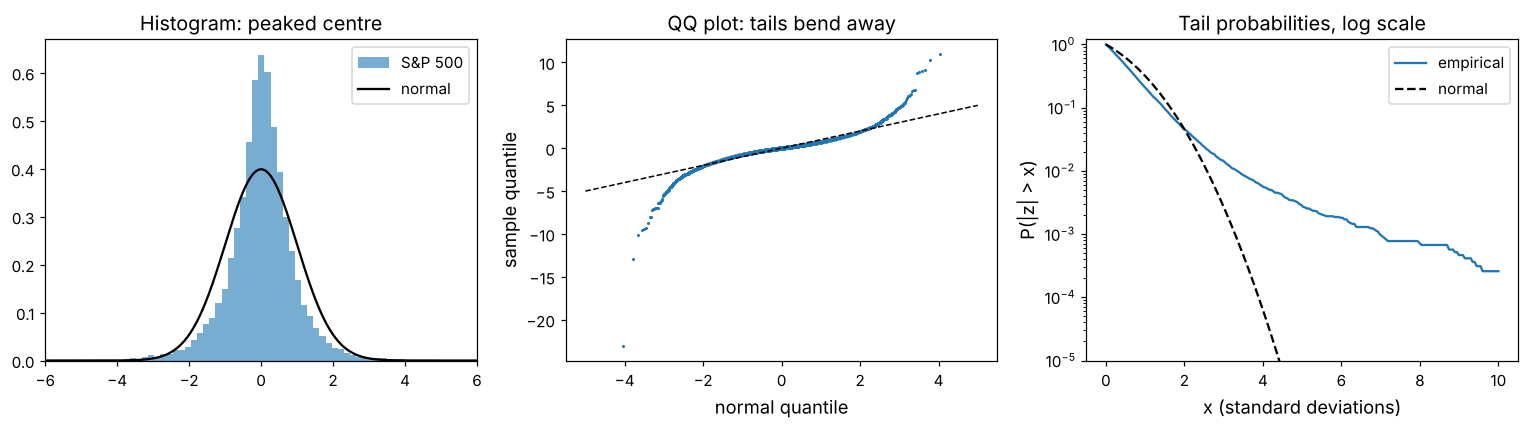

>3 sd:  274 days observed,    52.1844 expected if normal
>4 sd:  108 days observed,     1.2243 expected if normal
>5 sd:   54 days observed,     0.0111 expected if normal
>7 sd:   19 days observed,     0.0000 expected if normal


In [6]:
z = ((r - r.mean()) / r.std()).to_numpy()
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].hist(z, bins=200, density=True, alpha=0.6, label="S&P 500")
xs = np.linspace(-6, 6, 500); ax[0].plot(xs, stats.norm.pdf(xs), "k", label="normal")
ax[0].set_xlim(-6, 6); ax[0].legend(); ax[0].set_title("Histogram: peaked centre")
q_emp = np.sort(z); q_norm = stats.norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))
ax[1].plot(q_norm, q_emp, ".", ms=2); ax[1].plot([-5, 5], [-5, 5], "k--", lw=1)
ax[1].set_xlabel("normal quantile"); ax[1].set_ylabel("sample quantile"); ax[1].set_title("QQ plot: tails bend away")
grid = np.linspace(0, 10, 200)
ax[2].semilogy(grid, [(np.abs(z) > g).mean() for g in grid], label="empirical")
ax[2].semilogy(grid, 2 * stats.norm.sf(grid), "k--", label="normal")
ax[2].set_ylim(1e-5, 1.2); ax[2].set_xlabel("x (standard deviations)"); ax[2].set_ylabel("P(|z| > x)"); ax[2].legend()
ax[2].set_title("Tail probabilities, log scale")
save_fig("fat_tails"); plt.show()

for k in [3, 4, 5, 7]:
    print(f">{k} sd: {np.sum(np.abs(z) > k):4d} days observed, {len(z) * 2 * stats.norm.sf(k):10.4f} expected if normal")
R["n5sd"] = int(np.sum(np.abs(z) > 5)); R["e5sd"] = f"{len(z) * 2 * stats.norm.sf(5):.3f}"

![Figure 1-2. Three views of the tails. The QQ plot bends away from the line at both ends, and on the log scale (right) the empirical tail stays far above the normal one.](images/fat_tails.png)

There were 54 days beyond five standard deviations; a normal distribution predicts 0.011 in the whole sample. A model that assumes normality underestimates the probability of a crash by orders of magnitude.

## Stylised fact 2: no linear predictability, strong volatility predictability

### The autocorrelation function, from scratch

:::math
The sample autocorrelation at lag $k$ measures how today's value relates to the value $k$ days ago:

$$\hat\rho_k = \frac{\sum_{t=k+1}^{n} (x_t - \bar x)(x_{t-k} - \bar x)}{\sum_{t=1}^{n} (x_t - \bar x)^2}.$$

If the series were independent, each $\hat\rho_k$ would be approximately $\mathcal N(0, 1/n)$, so about 95% of them fall inside $\pm 1.96/\sqrt{n}$. To test many lags at once, the **Ljung–Box** statistic adds up their squares:

$$Q(m) = n(n + 2)\sum_{k=1}^{m}\frac{\hat\rho_k^2}{n - k} \sim \chi^2_m \quad \text{under independence}.$$
:::

matches statsmodels: True


Ljung–Box (10 lags), returns:   Q = 96.4, p = 2.81e-16
Ljung–Box (10 lags), |returns|: Q = 6884.5, p = 0


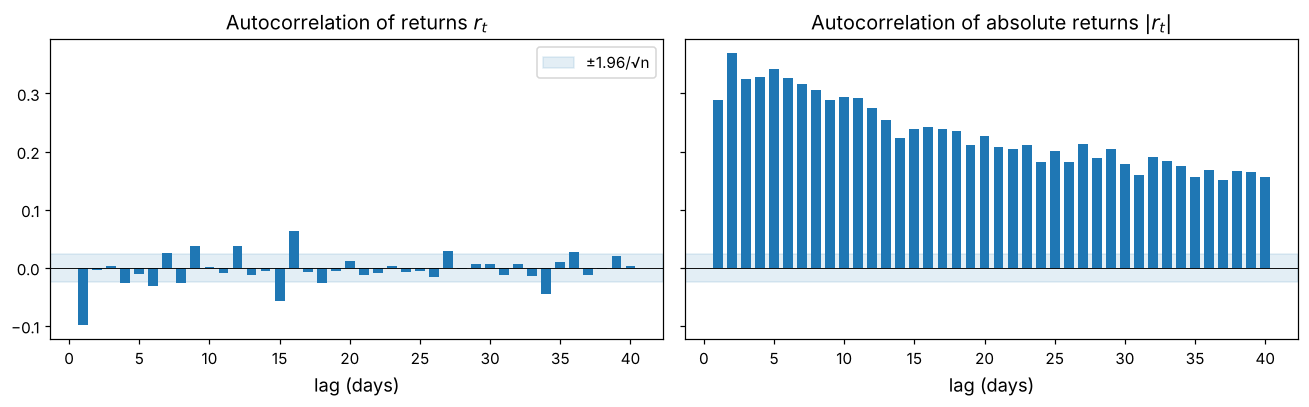

In [7]:
def acf(x, nlags):
    x = np.asarray(x, float) - np.mean(x)
    den = np.sum(x * x)
    return np.array([np.sum(x[k:] * x[:-k]) / den for k in range(1, nlags + 1)])

def ljung_box(x, m):
    n = len(x); rho = acf(x, m)
    Q = n * (n + 2) * np.sum(rho**2 / (n - np.arange(1, m + 1)))
    return Q, stats.chi2.sf(Q, m)

r2000 = r.loc["2000":]                           # the modern market
lags = 40
a_r, a_abs = acf(r2000, lags), acf(np.abs(r2000), lags)
band = 1.96 / np.sqrt(len(r2000))
from statsmodels.tsa.stattools import acf as sm_acf
print("matches statsmodels:", np.allclose(a_r, sm_acf(r2000, nlags=lags, fft=False)[1:]))
print("Ljung–Box (10 lags), returns:   Q = %.1f, p = %.3g" % ljung_box(r2000, 10))
print("Ljung–Box (10 lags), |returns|: Q = %.1f, p = %.3g" % ljung_box(np.abs(r2000), 10))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, vals, ttl in [(ax[0], a_r, "returns $r_t$"), (ax[1], a_abs, "absolute returns $|r_t|$")]:
    a.bar(range(1, lags + 1), vals, width=0.7)
    a.axhspan(-band, band, color="tab:blue", alpha=0.12, label="±1.96/√n")
    a.axhline(0, color="k", lw=0.6); a.set_title("Autocorrelation of " + ttl); a.set_xlabel("lag (days)")
ax[0].legend(); save_fig("acf"); plt.show()
R["acf1"] = f"{a_r[0]:+.3f}"; R["acf_abs1"] = f"{a_abs[0]:.2f}"; R["acf_abs40"] = f"{a_abs[-1]:.2f}"

![Figure 1-3. Left: returns themselves are nearly uncorrelated (the first lag is slightly negative). Right: the size of returns is strongly and persistently autocorrelated, the signature of volatility clustering.](images/acf.png)

Since 2000 the first-lag autocorrelation of returns is -0.098. That is statistically detectable (the band is only about ±0.02 with this much data) but economically tiny: it explains about 1% of the variance of tomorrow's return, and trading on it daily costs more than it earns (Chapter 2 shows why costs matter). You cannot predict tomorrow's direction from today's in any useful linear way. But the autocorrelation of *absolute* returns starts at 0.29 and is still 0.16 after 40 days. Volatility is predictable even though direction is not. That asymmetry is why volatility forecasting (Chapter 3) works far better than return forecasting.

:::quant
Both facts appear together in almost every liquid market and have a simple story: prices move when new information arrives, information arrives in bursts (earnings seasons, crises, central-bank meetings), and competition among traders removes predictable *directions* but not predictable *uncertainty*. A model of returns that ignores clustering, such as a constant-volatility random walk, mis-states risk every day.
:::

### The leverage effect: falls raise volatility

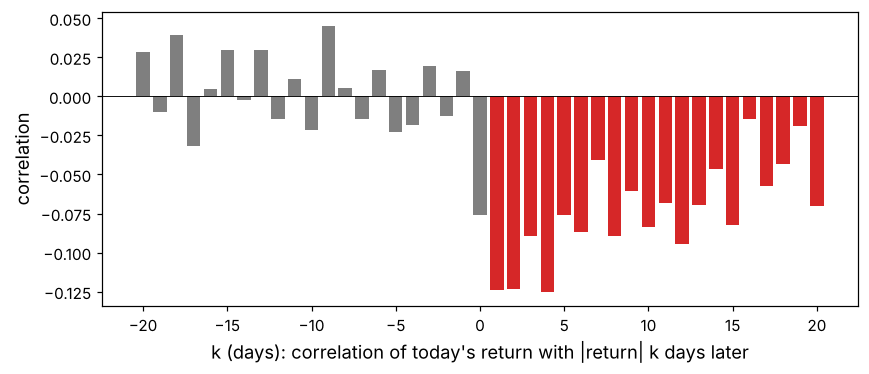

In [8]:
ks = np.arange(-20, 21)
lev = [r2000.corr(np.abs(r2000).shift(-k)) for k in ks]       # corr(r_t, |r_{t+k}|)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(ks, lev, color=["tab:gray" if k <= 0 else "tab:red" for k in ks])
ax.axhline(0, color="k", lw=0.6); ax.set_xlabel("k (days): correlation of today's return with |return| k days later")
ax.set_ylabel("correlation"); save_fig("leverage"); plt.show()
R["lev5"] = f"{np.mean([lev[list(ks).index(k)] for k in range(1, 6)]):+.2f}"

![Figure 1-4. Today's return is negatively correlated with future volatility (red bars, k > 0), but future returns tell nothing about past volatility (grey). Falls are followed by turbulence; rallies by calm.](images/leverage.png)

The average correlation between today's return and the size of returns over the next five days is -0.11. Falling markets become more volatile. The name comes from an old explanation (a falling share price raises a firm's debt-to-equity leverage), but the effect is too large for that story alone; panic selling and risk-management rules that cut positions after losses amplify it.

## Stylised fact 3: aggregational Gaussianity

Add up many daily returns into weekly, monthly or quarterly returns and the distribution becomes closer to normal (the central limit theorem at work), although never exactly, because of clustering.

In [9]:
ff_mkt = np.log1p(ff["mkt_rf"] + ff["rf"])                      # total US market log return, 1926–
horizons = {"daily": 1, "weekly": 5, "monthly": 21, "quarterly": 63, "yearly": 252}
rows = []
for name, h in horizons.items():
    agg = ff_mkt.rolling(h).sum().iloc[h - 1::h]                 # non-overlapping sums
    mm = moments(agg)
    rows.append({"horizon": name, "obs": mm["n"], "skew": mm["skew"], "kurtosis": mm["kurt"]})
agg_tab = pd.DataFrame(rows).set_index("horizon")
print(agg_tab.round(2))
R["k_daily_ff"] = f"{agg_tab.loc['daily', 'kurtosis']:.0f}"; R["k_month_ff"] = f"{agg_tab.loc['monthly', 'kurtosis']:.1f}"

             obs  skew  kurtosis
horizon                         
daily      26338 -0.46     19.99
weekly      5267 -0.77     11.47
monthly     1254 -0.92      9.52
quarterly    418 -0.63      7.33
yearly       104 -1.16      6.99


Over a century of US data, kurtosis falls from about 20 at the daily horizon to 9.5 at the monthly one. Monthly returns are closer to normal, though still fat-tailed (the 1930s dominate the monthly tails), which is one reason many asset-pricing studies work with monthly data. Note also that the yearly row has fewer than 100 observations: long horizons mean small samples.

## The same facts in seven assets

In [10]:
ar = np.log(assets).diff()
rows = []
for c in ar.columns:
    x = ar[c].dropna()
    mm = moments(x)
    rows.append({"asset": c, "years": round(len(x) / 252, 1), "ann vol": mm["sd"] * np.sqrt(252),
                 "skew": mm["skew"], "kurtosis": mm["kurt"],
                 "acf1 r": acf(x, 1)[0], "acf1 |r|": acf(np.abs(x), 1)[0],
                 "LB |r| p": ljung_box(np.abs(x), 10)[1]})
facts = pd.DataFrame(rows).set_index("asset")
print(facts.round(3))

          years  ann vol   skew  kurtosis  acf1 r  acf1 |r|  LB |r| p
asset                                                                
AAPL       18.8    0.321 -0.189     9.259  -0.021     0.213       0.0
BTC-USD    17.6    0.551 -0.703    15.024  -0.022     0.213       0.0
EEM        18.8    0.281  0.149    18.643  -0.108     0.304       0.0
EURUSD=X   19.9    0.112  0.662   111.147  -0.197     0.356       0.0
GLD        18.8    0.185 -0.497    10.118  -0.033     0.154       0.0
SPY        18.8    0.190 -0.069    17.098  -0.089     0.325       0.0
TLT        18.8    0.144 -0.052     6.468  -0.023     0.238       0.0


Stocks, bonds, gold, emerging markets, a single stock, a currency and Bitcoin differ hugely in volatility, but every one has excess kurtosis and strongly positive autocorrelation of absolute returns (Ljung–Box p-values of zero). One row looks wrong, though: EUR/USD has a kurtosis above 100 and a lag-1 autocorrelation near −0.2, far from the others.

### Free data is dirty: catching bad ticks

A huge move that is reversed the next day is the fingerprint of a **bad tick**, a wrong price in the data feed, not a real market move.

In [11]:
eur_px = assets["EURUSD=X"].dropna()
eur = np.log(eur_px).diff()
spike = (eur.abs() > 0.04) & (eur.shift(-1).abs() > 0.04) & (np.sign(eur) != np.sign(eur.shift(-1)))
print("suspicious days:", [d.date().isoformat() for d in eur.index[spike]])
print(eur_px.loc["2008-10-06":"2008-10-10"].round(4).to_dict())
clean_px = eur_px.mask(spike).ffill()              # drop the bad print, carry the last good price
eur_clean = np.log(clean_px).diff().dropna()
before, after = moments(eur.dropna()), moments(eur_clean)
print(f"kurtosis {before['kurt']:.0f} → {after['kurt']:.1f};  lag-1 autocorrelation {acf(eur.dropna(), 1)[0]:+.3f} → {acf(eur_clean, 1)[0]:+.3f}")
R["eur_k0"] = f"{before['kurt']:.0f}"; R["eur_k1"] = f"{after['kurt']:.1f}"; R["eur_spikes"] = int(spike.sum())

suspicious days: ['2008-01-08', '2008-02-08', '2008-09-08', '2008-10-08', '2008-12-08']
{Timestamp('2008-10-06 00:00:00'): 1.3505, Timestamp('2008-10-07 00:00:00'): 1.3588, Timestamp('2008-10-08 00:00:00'): 1.4957, Timestamp('2008-10-09 00:00:00'): 1.3598, Timestamp('2008-10-10 00:00:00'): 1.3398}
kurtosis 108 → 5.9;  lag-1 autocorrelation -0.179 → -0.016


All of them fall on the 8th day of a month in 2008, which points to a date-format mix-up in the source rather than real trades. Removing these 5 bad prints drops EUR/USD's kurtosis from 108 to 5.9 and its fake mean reversion disappears. A mean-reversion strategy backtested on the raw data would have “earned” money from errors that were never tradable.

:::trap
Always look at the largest moves of a new dataset before modelling it. Bad ticks, missing splits, stale prices and wrong time stamps are common in free data, and they create exactly the patterns (fat tails, reversals, fake predictability) that a model loves to exploit.
:::

With clean data the picture is uniform. These are the **stylised facts**, catalogued by Rama Cont (2001): they hold so widely that any model you build must reproduce them.

## Is the market a random walk? The variance-ratio test

:::math
If log prices follow a random walk, the variance of $q$-day returns is exactly $q$ times the variance of one-day returns. The **variance ratio**

$$\text{VR}(q) = \frac{\operatorname{Var}(r_t + r_{t-1} + \dots + r_{t-q+1})}{q \operatorname{Var}(r_t)} \approx 1 + 2\sum_{k=1}^{q-1}\Big(1 - \frac{k}{q}\Big)\rho_k$$

is 1 under a random walk, above 1 if returns trend (positive autocorrelations) and below 1 if they mean-revert. Lo and MacKinlay (1988) showed that under the random walk with constant variance, $z = (\text{VR}(q) - 1)\big/\sqrt{2(2q - 1)(q - 1)/(3qn)}$ is approximately standard normal.
:::

In [12]:
def variance_ratio(x, q):
    x = np.asarray(x, float); n = len(x)
    xq = np.convolve(x, np.ones(q), mode="valid")                # overlapping q-day sums
    vr = xq.var(ddof=1) / (q * x.var(ddof=1))
    z = (vr - 1) / np.sqrt(2 * (2 * q - 1) * (q - 1) / (3 * q * n))
    return vr, z

qs = [2, 5, 10, 21, 63, 126, 252]
vr_tab = pd.DataFrame({era: [variance_ratio(r.loc[a:b], q)[0] for q in qs]
                       for era, (a, b) in {"1950–1979": ("1950", "1979"), "1980–1999": ("1980", "1999"), "2000–2026": ("2000", "2026")}.items()},
                      index=pd.Index(qs, name="q (days)"))
print(vr_tab.round(3))
R["vr2_early"] = f"{vr_tab.iloc[0, 0]:.2f}"; R["vr2_late"] = f"{vr_tab.iloc[0, 2]:.2f}"

          1950–1979  1980–1999  2000–2026
q (days)                                 
2             1.177      1.038      0.902
5             1.262      0.983      0.828
10            1.285      0.938      0.765
21            1.340      0.892      0.749
63            1.327      0.849      0.664
126           1.512      0.761      0.714
252           1.524      0.700      0.778


In 1950–1979 the two-day variance ratio was 1.18: index returns had positive autocorrelation (a symptom of stale prices of small stocks that traded rarely). Since 2000 it is 0.90, slightly *below* one. The market became more efficient as trading got cheaper and faster, which is a pattern you will see again and again: **predictability that is easy to find gets traded away**.

## Maximum likelihood: fitting a fat-tailed distribution

If the normal distribution is wrong, which distribution is better? A standard choice is the **Student-t**, whose tails decay like a power law instead of exponentially. We fit it by **maximum likelihood**: choose the parameters that make the observed data most probable.

:::math
For independent data with density $f(x \mid \theta)$, the log-likelihood is $\ell(\theta) = \sum_t \ln f(x_t \mid \theta)$ and the maximum-likelihood estimate is $\hat\theta = \arg\max_\theta \ell(\theta)$. For the normal distribution $\ell(\mu, \sigma) = -\tfrac n2 \ln(2\pi\sigma^2) - \sum_t (x_t - \mu)^2 / (2\sigma^2)$, and setting the derivatives to zero gives the sample mean and the (divide-by-$n$) variance. For a location–scale Student-t with $\nu$ degrees of freedom,

$$f(x \mid \mu, s, \nu) = \frac{\Gamma\!\big(\tfrac{\nu+1}{2}\big)}{\Gamma\!\big(\tfrac{\nu}{2}\big)\sqrt{\nu\pi}\,s}\left(1 + \frac{1}{\nu}\Big(\frac{x - \mu}{s}\Big)^2\right)^{-\frac{\nu+1}{2}},$$

which has no closed-form maximum, so we maximise it numerically. Models with different numbers of parameters $k$ are compared with the **Akaike information criterion** $\text{AIC} = 2k - 2\ell(\hat\theta)$ (lower is better).
:::

In [13]:
x = r2000.to_numpy()

def nll_t(params):
    mu, log_s, log_nu = params
    s, nu = np.exp(log_s), np.exp(log_nu) + 2.0          # keep s > 0 and nu > 2 (finite variance)
    zz = (x - mu) / s
    ll = (special.gammaln((nu + 1) / 2) - special.gammaln(nu / 2) - 0.5 * np.log(nu * np.pi) - np.log(s)
          - (nu + 1) / 2 * np.log1p(zz**2 / nu))
    return -ll.sum()

res = optimize.minimize(nll_t, x0=[x.mean(), np.log(x.std()), np.log(3.0)], method="Nelder-Mead",
                        options={"xatol": 1e-9, "fatol": 1e-9, "maxiter": 4000})
mu_t, s_t, nu_t = res.x[0], np.exp(res.x[1]), np.exp(res.x[2]) + 2
ll_t = -res.fun
mu_n, sd_n = x.mean(), x.std()
ll_n = stats.norm.logpdf(x, mu_n, sd_n).sum()
print(f"Student-t: mu={mu_t:.5f}  s={s_t:.4f}  nu={nu_t:.2f}  logL={ll_t:.0f}  AIC={2*3 - 2*ll_t:.0f}")
print(f"Normal:    mu={mu_n:.5f}  sd={sd_n:.4f}              logL={ll_n:.0f}  AIC={2*2 - 2*ll_n:.0f}")
print("scipy.stats.t.fit agrees:", np.round(stats.t.fit(x), 4))
R["nu"] = f"{nu_t:.1f}"; R["daic"] = f"{(2*2 - 2*ll_n) - (2*3 - 2*ll_t):,.0f}"

for loss in [0.03, 0.05, 0.08]:
    p_n = stats.norm.cdf(-loss, mu_n, sd_n); p_t = stats.t.cdf(-loss, nu_t, mu_t, s_t); p_e = np.mean(x < -loss)
    print(f"P(daily loss worse than {loss:.0%}): normal {p_n:.2e}  t {p_t:.2e}  empirical {p_e:.2e}"
          f"   → once every {1/(252*p_n):,.0f} / {1/(252*p_t):,.1f} / {1/(252*max(p_e,1e-12)):,.1f} years")

Student-t: mu=0.00068  s=0.0070  nu=2.67  logL=21190  AIC=-42373
Normal:    mu=0.00024  sd=0.0121              logL=20210  AIC=-40415


scipy.stats.t.fit agrees: [2.6709e+00 7.0000e-04 7.0000e-03]
P(daily loss worse than 3%): normal 6.25e-03  t 1.40e-02  empirical 1.54e-02   → once every 1 / 0.3 / 0.3 years
P(daily loss worse than 5%): normal 1.67e-05  t 3.99e-03  empirical 3.41e-03   → once every 238 / 1.0 / 1.2 years
P(daily loss worse than 8%): normal 1.71e-11  t 1.19e-03  empirical 7.41e-04   → once every 231,624,404 / 3.3 / 5.4 years


The fitted Student-t has 2.7 degrees of freedom (a normal is the limit $\nu \to \infty$) and improves the AIC by 1,958 points, an overwhelming margin. The tail probabilities show what is at stake: since 2000, a normal model says a daily loss worse than 5% should happen about once in two centuries, and a loss worse than 8% once in hundreds of millions of years; the data show the first about once a year and the second about once every five years, much as the Student-t predicts.

:::trap
The Student-t fixes the tails but still treats every day as drawn from the same distribution. Real returns are closer to “normal-ish with a volatility that changes over time”: divide each return by a good volatility forecast and most of the excess kurtosis disappears. Chapter 3 shows this with GARCH. Fat tails are partly a symptom of volatility clustering.
:::

## How much can a sample tell you?

Now the most important section of the chapter. Suppose a strategy has a true annual Sharpe ratio of 0.5, a respectable level. How long must you observe it before the data prove it is positive?

:::math
The t-statistic of a mean return is $t = \bar x \big/ (s/\sqrt n)$. Written with the annual Sharpe ratio $\text{SR} = \sqrt{252}\,\bar x / s$ and the number of years $T = n/252$:

$$t = \text{SR}\,\sqrt{T}.$$

For the usual 5% significance level we need $t \geq 2$, so the years required are

$$T \geq \Big(\frac{2}{\text{SR}}\Big)^2.$$

A Sharpe ratio of 0.5 needs **16 years** of data; 0.3 needs 44 years; even an excellent 1.0 needs 4 years.
:::

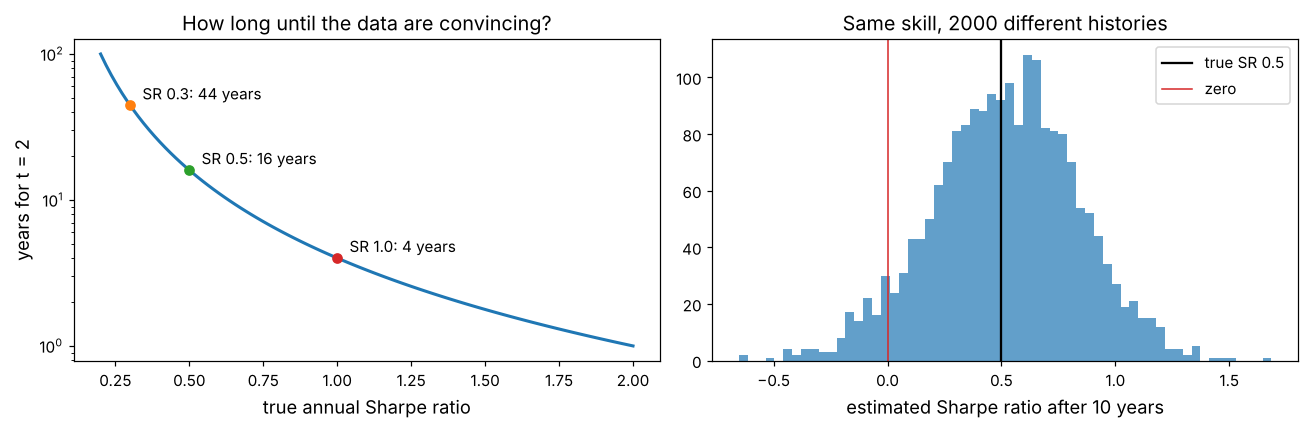

In [14]:
srs = np.linspace(0.2, 2.0, 100)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(srs, (2 / srs) ** 2, lw=2)
for s_ in [0.3, 0.5, 1.0]:
    ax[0].plot(s_, (2 / s_) ** 2, "o"); ax[0].annotate(f"SR {s_}: {(2/s_)**2:.0f} years", (s_, (2 / s_) ** 2), xytext=(8, 4), textcoords="offset points")
ax[0].set_yscale("log"); ax[0].set_xlabel("true annual Sharpe ratio"); ax[0].set_ylabel("years for t = 2"); ax[0].set_title("How long until the data are convincing?")

# 2000 simulated managers with true SR 0.5 for 10 years
T_years, n_sims, sr_true = 10, 2000, 0.5
daily = rng.normal(sr_true / np.sqrt(252) * 0.01, 0.01, size=(n_sims, 252 * T_years))
sr_hat = daily.mean(1) / daily.std(1, ddof=1) * np.sqrt(252)
ax[1].hist(sr_hat, bins=60, alpha=0.7)
ax[1].axvline(sr_true, color="k", lw=1.5, label="true SR 0.5"); ax[1].axvline(0, color="tab:red", lw=1, label="zero")
ax[1].set_xlabel("estimated Sharpe ratio after 10 years"); ax[1].set_title("Same skill, 2000 different histories"); ax[1].legend()
save_fig("sample_size"); plt.show()
R["share_neg"] = f"{np.mean(sr_hat < 0):.0%}"
R["sr_5_95"] = f"{np.percentile(sr_hat, 5):.2f} to {np.percentile(sr_hat, 95):.2f}"

![Figure 1-5. Left: years of data needed for a t-statistic of 2. Right: 2000 managers with identical true skill (SR 0.5), observed for 10 years each.](images/sample_size.png)

Ten years of a genuinely skilled strategy produce estimated Sharpe ratios anywhere from -0.03 to 1.02 (5th to 95th percentile), and 6% of the managers end the decade with a negative record. Keep this picture in mind whenever you see a backtest: the estimation error of a Sharpe ratio is about $1/\sqrt{T}$, so roughly ±0.3 for ten years.

## The bootstrap, and why blocks matter

The bootstrap estimates uncertainty by resampling the data. The **iid bootstrap** resamples single days; it destroys any dependence between days. The **block bootstrap** resamples blocks of consecutive days, keeping volatility clusters intact within each block.

In [15]:
def iid_bootstrap(x, stat, B, rng):
    n = len(x); idx = rng.integers(0, n, (B, n))
    return np.array([stat(x[i]) for i in idx])

def block_bootstrap(x, stat, B, block, rng):
    n = len(x); n_blocks = int(np.ceil(n / block))
    starts = rng.integers(0, n - block + 1, (B, n_blocks))
    idx = (starts[:, :, None] + np.arange(block)).reshape(B, -1)[:, :n]
    return np.array([stat(x[i]) for i in idx])

ann_vol = lambda v: v.std(ddof=1) * np.sqrt(252)
x5 = r.loc["2005":"2009"].to_numpy()                   # five years including the 2008 crisis
b_iid = iid_bootstrap(x5, ann_vol, 2000, rng)
b_blk = block_bootstrap(x5, ann_vol, 2000, 63, rng)
print(f"annual vol 2005–2009: {ann_vol(x5):.1%}")
print(f"95% interval, iid bootstrap:   [{np.percentile(b_iid, 2.5):.1%}, {np.percentile(b_iid, 97.5):.1%}]")
print(f"95% interval, block bootstrap: [{np.percentile(b_blk, 2.5):.1%}, {np.percentile(b_blk, 97.5):.1%}]")
R["w_iid"] = f"{np.percentile(b_iid, 97.5) - np.percentile(b_iid, 2.5):.1%}"
R["w_blk"] = f"{np.percentile(b_blk, 97.5) - np.percentile(b_blk, 2.5):.1%}"

annual vol 2005–2009: 24.1%
95% interval, iid bootstrap:   [21.9%, 26.3%]
95% interval, block bootstrap: [15.9%, 33.4%]


Over 2005–2009 the iid bootstrap gives a 95% interval of width 4.4% for the annual volatility; the block bootstrap, which keeps the 2008 turbulence together in blocks, gives 17.5%. Ignoring clustering makes you overconfident. Use blocks (here three months) whenever you bootstrap financial time series.

## Luck versus skill: multiple testing

Here is the trap that sinks more quant research than any other. Test many strategies on the same data, keep the best one, and its backtest will look good **even if none of them has any skill**.

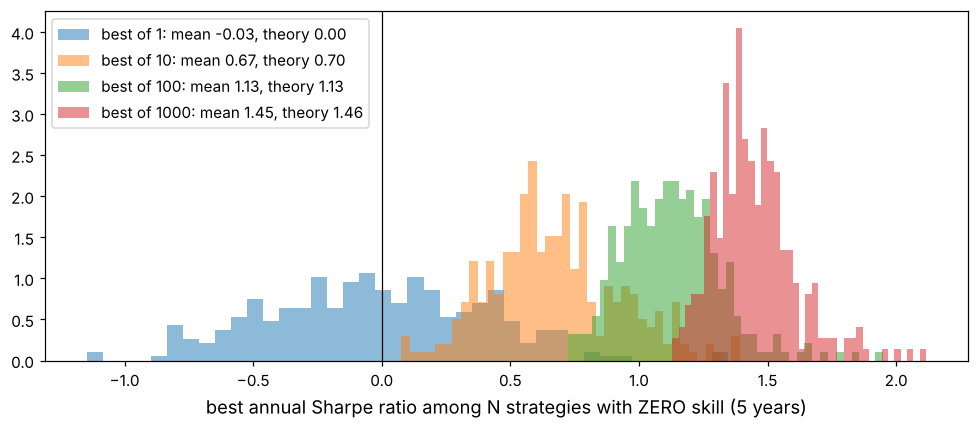

In [16]:
T_years = 5
n_days = 252 * T_years
best_by_N = {}
for N in [1, 10, 100, 1000]:
    best = []
    for rep in range(300):                                        # 300 repetitions of "try N zero-skill strategies"
        sims = rng.normal(0, 0.01, size=(N, n_days))
        best.append((sims.mean(1) / sims.std(1, ddof=1)).max() * np.sqrt(252))
    best_by_N[N] = np.array(best)
gamma = 0.5772156649
def expected_max_sr(N, T):
    if N == 1:
        return 0.0
    sd = 1 / np.sqrt(T)                                           # sd of an annual SR estimate under zero skill
    return sd * ((1 - gamma) * stats.norm.ppf(1 - 1 / N) + gamma * stats.norm.ppf(1 - 1 / (N * np.e)))

fig, ax = plt.subplots(figsize=(9, 4))
for N, v in best_by_N.items():
    ax.hist(v, bins=40, alpha=0.5, density=True, label=f"best of {N}: mean {v.mean():.2f}, theory {expected_max_sr(N, T_years):.2f}")
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("best annual Sharpe ratio among N strategies with ZERO skill (5 years)")
ax.legend(); save_fig("multiple_testing"); plt.show()
R["best1000"] = f"{best_by_N[1000].mean():.2f}"

![Figure 1-6. Every strategy here is pure noise. Yet the best of 100 has a five-year Sharpe ratio near 1, and the best of 1000 near 1.4. The theory in the legend (the expected maximum of N normal estimates) matches the simulation.](images/multiple_testing.png)

The best of 1000 worthless strategies shows a Sharpe ratio of 1.45 over five years. Researchers who try many parameter settings, signals or assets are running exactly this experiment, usually without counting the trials.

### The probabilistic and deflated Sharpe ratios

Bailey and López de Prado turned this into two practical tools.

:::math
The **probabilistic Sharpe ratio** is the probability that the true Sharpe ratio exceeds a benchmark $\text{SR}^*$, given an estimate $\widehat{\text{SR}}$ from $n$ observations (both measured per period, not annualised), with sample skewness $\hat\gamma_3$ and kurtosis $\hat\gamma_4$:

$$\text{PSR}(\text{SR}^*) = \Phi\!\left(\frac{(\widehat{\text{SR}} - \text{SR}^*)\sqrt{n - 1}}{\sqrt{1 - \hat\gamma_3\,\widehat{\text{SR}} + \frac{\hat\gamma_4 - 1}{4}\,\widehat{\text{SR}}^2}}\right).$$

Negative skew and fat tails widen the denominator, lowering confidence. The **deflated Sharpe ratio** is the PSR with the benchmark set to the Sharpe ratio you would expect from the best of $N$ trials with no skill:

$$\text{SR}^* = \sqrt{\operatorname{Var}[\widehat{\text{SR}}_k]}\,\Big((1 - \gamma)\,\Phi^{-1}\!\big(1 - \tfrac1N\big) + \gamma\,\Phi^{-1}\!\big(1 - \tfrac{1}{N e}\big)\Big),$$

where $\operatorname{Var}[\widehat{\text{SR}}_k]$ is the variance of the Sharpe ratios across the $N$ trials and $\gamma \approx 0.5772$ is the Euler–Mascheroni constant.
:::

In [17]:
def psr(returns, sr_star=0.0):
    x = np.asarray(returns, float); n = len(x)
    sr = x.mean() / x.std(ddof=1)
    g3 = stats.skew(x); g4 = stats.kurtosis(x, fisher=False)
    return stats.norm.cdf((sr - sr_star) * np.sqrt(n - 1) / np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr**2))

def dsr(returns, trial_srs):
    """trial_srs: per-period Sharpe ratios of all N strategies tried."""
    N = len(trial_srs)
    sr_star = np.std(trial_srs, ddof=1) * ((1 - gamma) * stats.norm.ppf(1 - 1 / N) + gamma * stats.norm.ppf(1 - 1 / (N * np.e)))
    return psr(returns, sr_star)

trials = rng.normal(0, 0.01, size=(200, n_days))              # 200 zero-skill backtests
per_sr = trials.mean(1) / trials.std(1, ddof=1)
best = trials[np.argmax(per_sr)]
print(f"best of 200: annual SR {per_sr.max() * np.sqrt(252):.2f}")
print(f"  PSR vs 0 (ignoring the search): {psr(best):.3f}")
print(f"  DSR (accounting for 200 trials): {dsr(best, per_sr):.3f}")
spy = np.log(assets["SPY"]).diff().dropna().to_numpy()
print(f"SPY 2005–2026: annual SR {spy.mean()/spy.std()*np.sqrt(252):.2f}, PSR vs 0 = {psr(spy):.3f}")
R["psr_best"] = f"{psr(best):.3f}"; R["dsr_best"] = f"{dsr(best, per_sr):.2f}"

best of 200: annual SR 1.19
  PSR vs 0 (ignoring the search): 0.996
  DSR (accounting for 200 trials): 0.414
SPY 2005–2026: annual SR 0.51, PSR vs 0 = 0.987


The best of 200 noise strategies has a PSR of 0.996: on its own its backtest “looks significant”. Its deflated Sharpe ratio, which knows that 200 strategies were tried, is 0.41: no evidence of skill. **Always record how many things you tried.** Chapter 5 adds a second tool, the probability of backtest overfitting.

::playground animations/luck_lab.html 690

The playground lets you change the number of strategies, the years of data and the true skill, and watch how often noise beats skill. It also compares normal and Student-t tails.

## Summary: what every model must respect

| Fact | Evidence in this chapter | Consequence |
|---|---|---|
| Heavy tails | kurtosis 28.2 (normal: 3); 54 days beyond 5 sd against 0.011 expected | Normal VaR underestimates crashes; use Student-t, historical or volatility-scaled models |
| No linear predictability | lag-1 autocorrelation -0.098 since 2000 | Direction forecasts are weak; demand strong evidence |
| Volatility clustering | autocorrelation of \|r\| 0.29 at lag 1, still 0.16 at lag 40 | Volatility is forecastable (Chapter 3); size positions by risk |
| Leverage effect | corr(r, future \|r\|) -0.11 | Risk rises after falls; downside protection costs more |
| Aggregational Gaussianity | kurtosis falls with horizon | Monthly data closer to normal; few observations at long horizons |
| Edges fade | variance ratio fell from 1.18 to 0.90 | Old anomalies decay; test out of sample and over time |
| Noise dominates | SR 0.5 needs about 16 years for t = 2 | Count trials, deflate Sharpe ratios, distrust short backtests |

## Exercises

:::exercise
1. Compute skewness and kurtosis of SPY returns *after* dividing each day's return by the standard deviation of the previous 21 days. How much of the excess kurtosis remains? (This previews Chapter 3.)
2. Repeat the variance-ratio table for TLT and for EURUSD. Which assets look trending or mean-reverting at the 1-month horizon?
3. Using the Fama–French market series since 1926, compute the 30-year rolling annual Sharpe ratio of the US market. How much does it vary?
4. Implement the **stationary bootstrap** (Politis and Romano), in which block lengths are random with a geometric distribution of mean 63 days, and compare its interval for the 2005–2009 volatility with the two above.
5. You tried 50 variations of a strategy and the best has a 6-year Sharpe ratio of 1.2, with the 50 Sharpe ratios having a standard deviation of 0.35 (annualised). Is it significant after deflation? Assume normal returns.
:::

<details><summary>Solutions</summary>

In [18]:
# 1
s = np.log(assets["SPY"]).diff().dropna()
scaled = (s / s.rolling(21).std().shift(1)).dropna()
print("raw kurtosis", round(moments(s)["kurt"], 1), "→ vol-scaled", round(moments(scaled)["kurt"], 1))

# 2
for c in ["TLT", "EURUSD=X"]:
    xx = np.log(assets[c]).diff().dropna()
    print(c, [round(variance_ratio(xx, q)[0], 3) for q in [2, 5, 21, 63]])

# 3
mk = ff["mkt_rf"]
roll_sr = (mk.rolling(252 * 30).mean() / mk.rolling(252 * 30).std() * np.sqrt(252)).dropna()
print(f"30-year Sharpe ranged from {roll_sr.min():.2f} to {roll_sr.max():.2f}")

# 4
def stationary_bootstrap(x, stat, B, mean_block, rng):
    n = len(x); out = np.empty(B); p = 1 / mean_block
    for b in range(B):
        idx = np.empty(n, int); idx[0] = rng.integers(n)
        new = rng.random(n) < p
        jumps = rng.integers(0, n, n)
        for t in range(1, n):
            idx[t] = jumps[t] if new[t] else (idx[t - 1] + 1) % n
        out[b] = stat(x[idx])
    return out
b_st = stationary_bootstrap(x5, ann_vol, 1000, 63, rng)
print(f"stationary bootstrap: [{np.percentile(b_st, 2.5):.1%}, {np.percentile(b_st, 97.5):.1%}]")

# 5
N, T, sr_best, sd_trials = 50, 6, 1.2, 0.35
sr_star = sd_trials * ((1 - gamma) * stats.norm.ppf(1 - 1 / N) + gamma * stats.norm.ppf(1 - 1 / (N * np.e)))
n_obs = 252 * T
z_ = (sr_best - sr_star) / np.sqrt(252) * np.sqrt(n_obs - 1) / np.sqrt(1 + 0.5 * (sr_best / np.sqrt(252)) ** 2)
print(f"benchmark SR* = {sr_star:.2f} (annual), DSR = {stats.norm.cdf(z_):.3f}")

raw kurtosis 17.1 → vol-scaled 7.0
TLT [np.float64(0.977), np.float64(0.906), np.float64(0.842), np.float64(0.8)]
EURUSD=X [np.float64(0.803), np.float64(0.663), np.float64(0.611), np.float64(0.536)]
30-year Sharpe ranged from 0.29 to 1.04


stationary bootstrap: [14.2%, 33.4%]
benchmark SR* = 0.80 (annual), DSR = 0.838


</details>

## What's next

You now know what returns look like and how little a short sample proves. Chapter 2 puts this to work: we build an honest backtester from scratch and test one of the oldest strategies in finance, trend following, with every bias the backtester can introduce shown and removed.